In [1]:
#import os
#os.chdir('..')
from FL import *
import matplotlib.pyplot as plt

In [2]:
def centerout_reachingtask(start=[0, 30], L=10, num_targ=8):
    tg = np.zeros((num_targ, 2))
    for i, angles in enumerate(np.linspace(0, 2 * pi, num_targ + 1)[:-1]):
        tg[i] = np.array([start[0] + cos(angles) * L, start[1] + sin(angles) * L])
    return tg

def ToCartesian(x, at3=False):
    elbowindex = 3 if at3 else 1
    if len(x.shape) == 1:
        s = x[0]
        e = x[elbowindex]
    else:
        s = x[:, 0]
        e = x[:, elbowindex]
    X = np.cos(s + e) * L2_CM + np.cos(s) * L1_CM  # segment lengths from FL.py
    Y = np.sin(s + e) * L2_CM + np.sin(s) * L1_CM

    return X, Y


In [3]:
def max_curvature(X, Y, dt, speed_fraction=0.1):
    """
    Maximal curvature of the hand path, kappa = |x'y'' - y'x''| / (x'^2 + y'^2)^(3/2),
    in 1/cm. Only where the hand speed is above `speed_fraction` of its peak:
    at the start and the end the speed goes to zero and kappa is undefined.
    Returns NaN for a path that is not finite (e.g. an unreachable target).
    """
    X, Y = np.asarray(X, float), np.asarray(Y, float)
    if not (np.all(np.isfinite(X)) and np.all(np.isfinite(Y))):
        return np.nan
    vx, vy = np.gradient(X, dt), np.gradient(Y, dt)
    ax, ay = np.gradient(vx, dt), np.gradient(vy, dt)
    speed = np.hypot(vx, vy)
    if speed.max() == 0:
        return np.nan
    moving = speed > speed_fraction * speed.max()
    kappa = np.abs(vx[moving] * ay[moving] - vy[moving] * ax[moving]) / speed[moving] ** 3
    return np.max(kappa)

In [4]:
THETA_S_GRID = np.arange(0, 70 + 5, 5)   # 0 to 70 deg included
THETA_E_GRID = np.arange(20, 130 + 5, 5)  # 20 to 130 deg included
DURATIONS = {10: .4, 20: .6}  # movement time [s] of each amplitude [cm]
DT = .01  # simulation step [s]
WP,WV,WRFL = 2e4,10,6e-5


def compute_max_curvature(amplitude):
    """
    Maximal hand-path curvature [1/cm] for each starting posture and direction,
    for center-out reaches of `amplitude` cm. Shape (shoulder, elbow, direction).
    NaN where the simulation fails or the target is out of reach.
    """
    duration = DURATIONS[amplitude]
    K = int(round(duration / DT))
    max_curv = np.full((len(THETA_S_GRID), len(THETA_E_GRID), 8), np.nan)
    for i, theta_s in enumerate(THETA_S_GRID):
        for j, theta_e in enumerate(THETA_E_GRID):
            start = ToCartesian(np.radians(np.array([theta_s, theta_e])))  # the grid is in degrees
            end = centerout_reachingtask(start=start, L=amplitude, num_targ=8)
            for direction in range(8):
                if not np.all(np.isfinite(compute_angles_from_cartesian(*end[direction]))):
                    continue  # target out of reach (more than 63 cm from the shoulder): stays NaN
                try:
                    X,Y,_,_ = simulate_FL(Duration = duration, Num_iter= K,starting_point = start,targets = end[direction], Activate_Noise = False, wp=WP, wv=WV, wr=WRFL)
                except Exception as exc:
                    print(f"{amplitude} cm, shoulder {theta_s}, elbow {theta_e}, direction {direction}: {exc}")
                    continue
                max_curv[i, j, direction] = max_curvature(X, Y, duration / K)
    return max_curv


MAX_CURVATURE = compute_max_curvature(20)

d:\thyriona\Desktop\Codes\My_research\WP1\Experiment_1\FL.py:84: RuntimeWarning: invalid value encountered in arccos
  shoulder_angle = np.arctan2(y, x) - np.arccos(
d:\thyriona\Desktop\Codes\My_research\WP1\Experiment_1\FL.py:88: RuntimeWarning: invalid value encountered in arccos
  elbow_angle = np.pi - np.arccos((l1**2 + l2**2 - r_squared) / (2 * l1 * l2))
d:\thyriona\Desktop\Codes\My_research\WP1\Experiment_1\FL.py:60: RuntimeWarning: invalid value encountered in power
  fl = np.exp(-(np.abs((l**1.55 - 1) / 0.81) ** 2.12))


20 cm, shoulder 65, elbow 130, direction 6: SVD did not converge
20 cm, shoulder 70, elbow 125, direction 6: SVD did not converge
20 cm, shoulder 70, elbow 130, direction 6: SVD did not converge


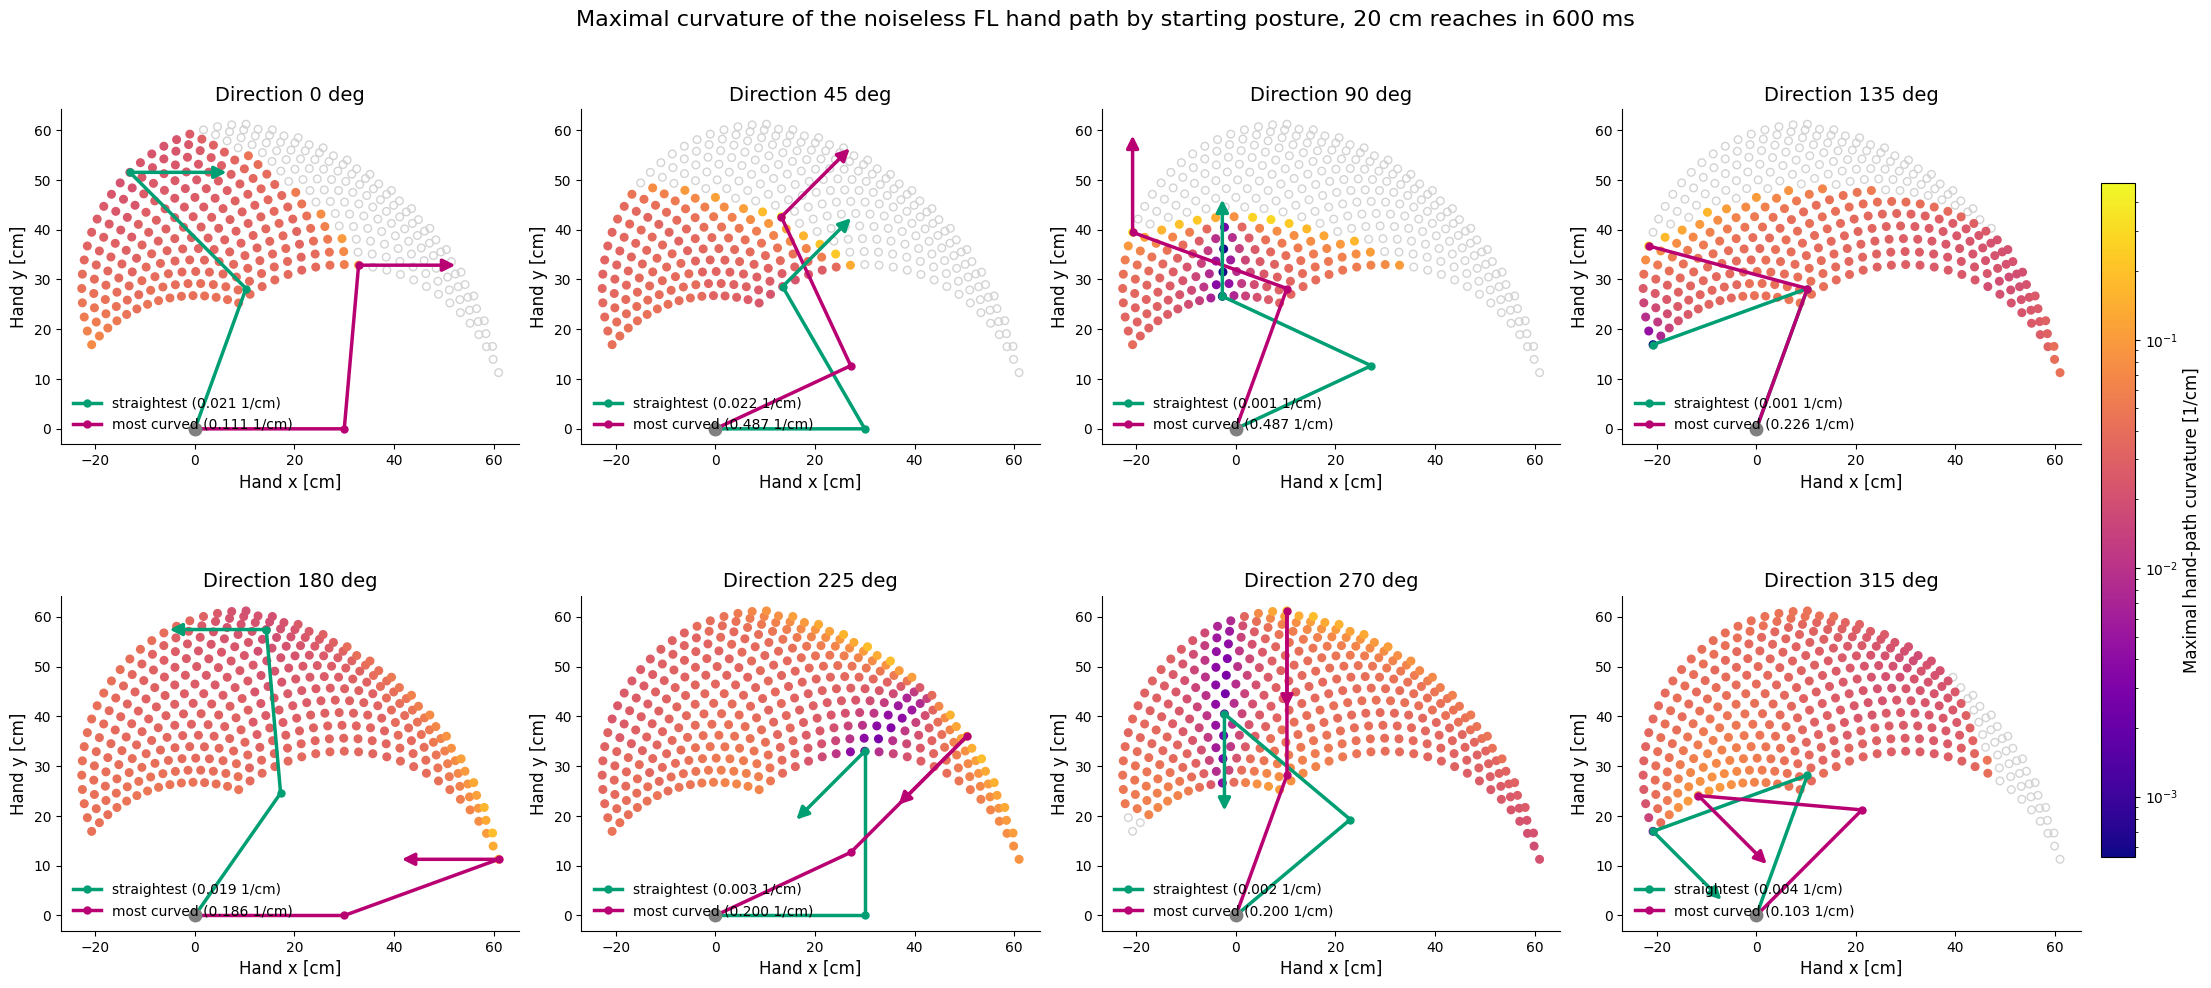

In [5]:
from matplotlib.colors import LogNorm

# Workspace view, as in Final_Code/cost_map_2directions.py: every starting posture
# is drawn where it puts the hand, coloured by the maximal curvature of the reach
# in that direction. The arms show the straightest and the most curved posture,
# with an arrow for the reach. Open grey circles: target out of reach.
L1, L2 = L1_CM, L2_CM  # segment lengths [cm], from FL.py
STRAIGHT_COLOR, CURVED_COLOR = "#009E73", "#B90072"

grid_s, grid_e = np.meshgrid(THETA_S_GRID, THETA_E_GRID, indexing="ij")
rad_s, rad_e = np.radians(grid_s), np.radians(grid_e)
start_x = L1 * np.cos(rad_s) + L2 * np.cos(rad_s + rad_e)  # hand position of each posture
start_y = L1 * np.sin(rad_s) + L2 * np.sin(rad_s + rad_e)


def draw_arm(ax, theta_s, theta_e, color, label, direction=None, amplitude=None):
    """The two links of a posture, and the reach that starts from it if a direction is given."""
    ts, te = np.radians(theta_s), np.radians(theta_e)
    elbow = np.array([np.cos(ts) * L1, np.sin(ts) * L1])
    hand = elbow + np.array([np.cos(ts + te) * L2, np.sin(ts + te) * L2])
    ax.plot([0, elbow[0], hand[0]], [0, elbow[1], hand[1]], color=color,
            linewidth=2.5, marker="o", markersize=5, zorder=3, label=label)
    if direction is not None:
        angle = direction * pi / 4
        ax.annotate("", xy=hand + amplitude * np.array([cos(angle), sin(angle)]),
                    xytext=hand, zorder=4,
                    arrowprops=dict(arrowstyle="-|>", color=color, linewidth=2.5,
                                    mutation_scale=18))


def plot_curvature_directions(max_curv, amplitude):
    """One workspace panel per direction, on a shared logarithmic colour scale."""
    finite = max_curv[np.isfinite(max_curv)]
    norm = LogNorm(vmin=finite.min(), vmax=finite.max())

    fig, axes = plt.subplots(2, 4, figsize=(22, 10), layout="constrained")
    for direction, ax in enumerate(axes.ravel()):
        kappa = max_curv[:, :, direction]
        reachable = np.isfinite(kappa)
        sc = ax.scatter(start_x[reachable], start_y[reachable], c=kappa[reachable],
                        cmap="plasma", norm=norm, s=30, zorder=2)
        ax.scatter(start_x[~reachable], start_y[~reachable], s=30, facecolors="none",
                   edgecolors="lightgrey", zorder=1)

        straightest = np.unravel_index(np.nanargmin(kappa), kappa.shape)
        most_curved = np.unravel_index(np.nanargmax(kappa), kappa.shape)
        for idx, color, name in ((straightest, STRAIGHT_COLOR, "straightest"),
                                 (most_curved, CURVED_COLOR, "most curved")):
            draw_arm(ax, THETA_S_GRID[idx[0]], THETA_E_GRID[idx[1]], color,
                     f"{name} ({kappa[idx]:.3f} 1/cm)", direction, amplitude)

        ax.plot(0, 0, marker="o", markersize=9, color="grey", zorder=5)  # shoulder
        ax.set_aspect("equal")
        ax.set_title(f"Direction {direction * 45} deg", fontsize=14)
        ax.set_xlabel("Hand x [cm]", fontsize=12)
        ax.set_ylabel("Hand y [cm]", fontsize=12)
        ax.legend(fontsize=10, loc="lower left", frameon=False)
        ax.spines[["top", "right"]].set_visible(False)

    cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.7, pad=0.01)
    cbar.set_label("Maximal hand-path curvature [1/cm]", fontsize=12)
    fig.suptitle(f"Maximal curvature of the noiseless FL hand path by starting posture, "
                 f"{amplitude} cm reaches in {DURATIONS[amplitude] * 1000:.0f} ms", fontsize=16)
    plt.show()


plot_curvature_directions(MAX_CURVATURE, 20)

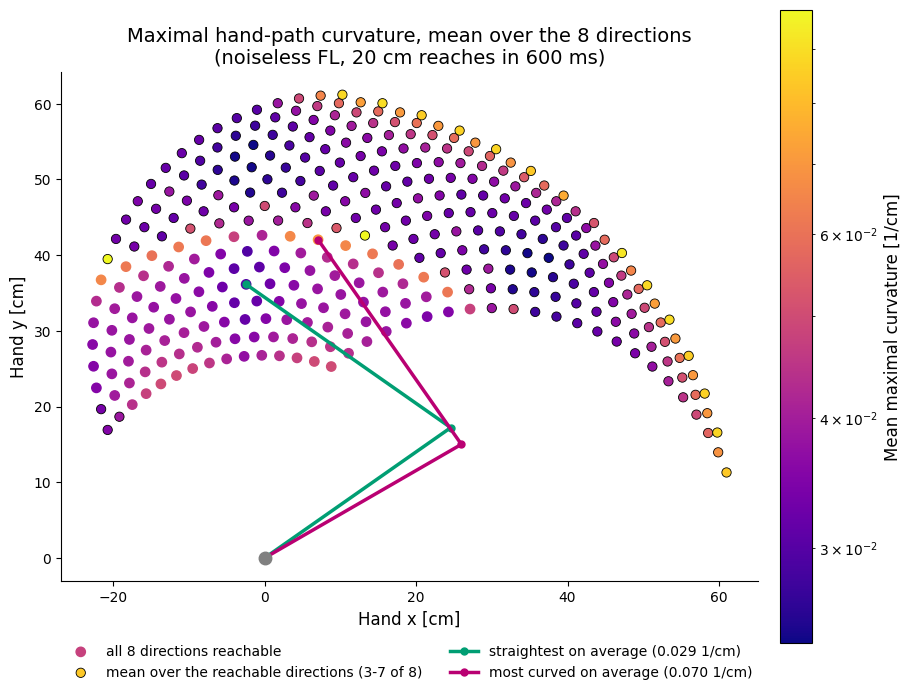

In [6]:
def plot_curvature_mean(max_curv, amplitude):
    """
    Maximal curvature averaged over the 8 directions, for each starting posture.
    Where some targets are out of reach, the mean is over the reachable directions
    only; those postures are outlined in black (number of directions in the legend).
    """
    mean_kappa = np.nanmean(max_curv, axis=2)
    n_reachable = np.sum(np.isfinite(max_curv), axis=2)
    full = n_reachable == 8
    partial = (n_reachable > 0) & ~full

    finite = mean_kappa[np.isfinite(mean_kappa)]
    norm = LogNorm(vmin=finite.min(), vmax=finite.max())

    fig, ax = plt.subplots(figsize=(9, 8), layout="constrained")
    sc = ax.scatter(start_x[full], start_y[full], c=mean_kappa[full], cmap="plasma",
                    norm=norm, s=45, zorder=2, label="all 8 directions reachable")
    if partial.any():
        ax.scatter(start_x[partial], start_y[partial], c=mean_kappa[partial], cmap="plasma",
                   norm=norm, s=45, edgecolors="black", linewidths=0.6, zorder=2,
                   label=f"mean over the reachable directions ({n_reachable[partial].min()}"
                         f"-{n_reachable[partial].max()} of 8)")

    # The postures with the lowest and the highest mean, among those reaching all 8.
    masked = np.where(full, mean_kappa, np.nan)
    for idx, color, name in ((np.unravel_index(np.nanargmin(masked), masked.shape), STRAIGHT_COLOR, "straightest"),
                             (np.unravel_index(np.nanargmax(masked), masked.shape), CURVED_COLOR, "most curved")):
        draw_arm(ax, THETA_S_GRID[idx[0]], THETA_E_GRID[idx[1]], color,
                 f"{name} on average ({mean_kappa[idx]:.3f} 1/cm)")

    ax.plot(0, 0, marker="o", markersize=9, color="grey", zorder=5)  # shoulder
    ax.set_aspect("equal")
    ax.set_xlabel("Hand x [cm]", fontsize=12)
    ax.set_ylabel("Hand y [cm]", fontsize=12)
    ax.set_title(f"Maximal hand-path curvature, mean over the 8 directions\n"
                 f"(noiseless FL, {amplitude} cm reaches in {DURATIONS[amplitude] * 1000:.0f} ms)", fontsize=14)
    ax.legend(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    cbar = fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.01)
    cbar.set_label("Mean maximal curvature [1/cm]", fontsize=12)
    plt.show()


plot_curvature_mean(MAX_CURVATURE, 20)

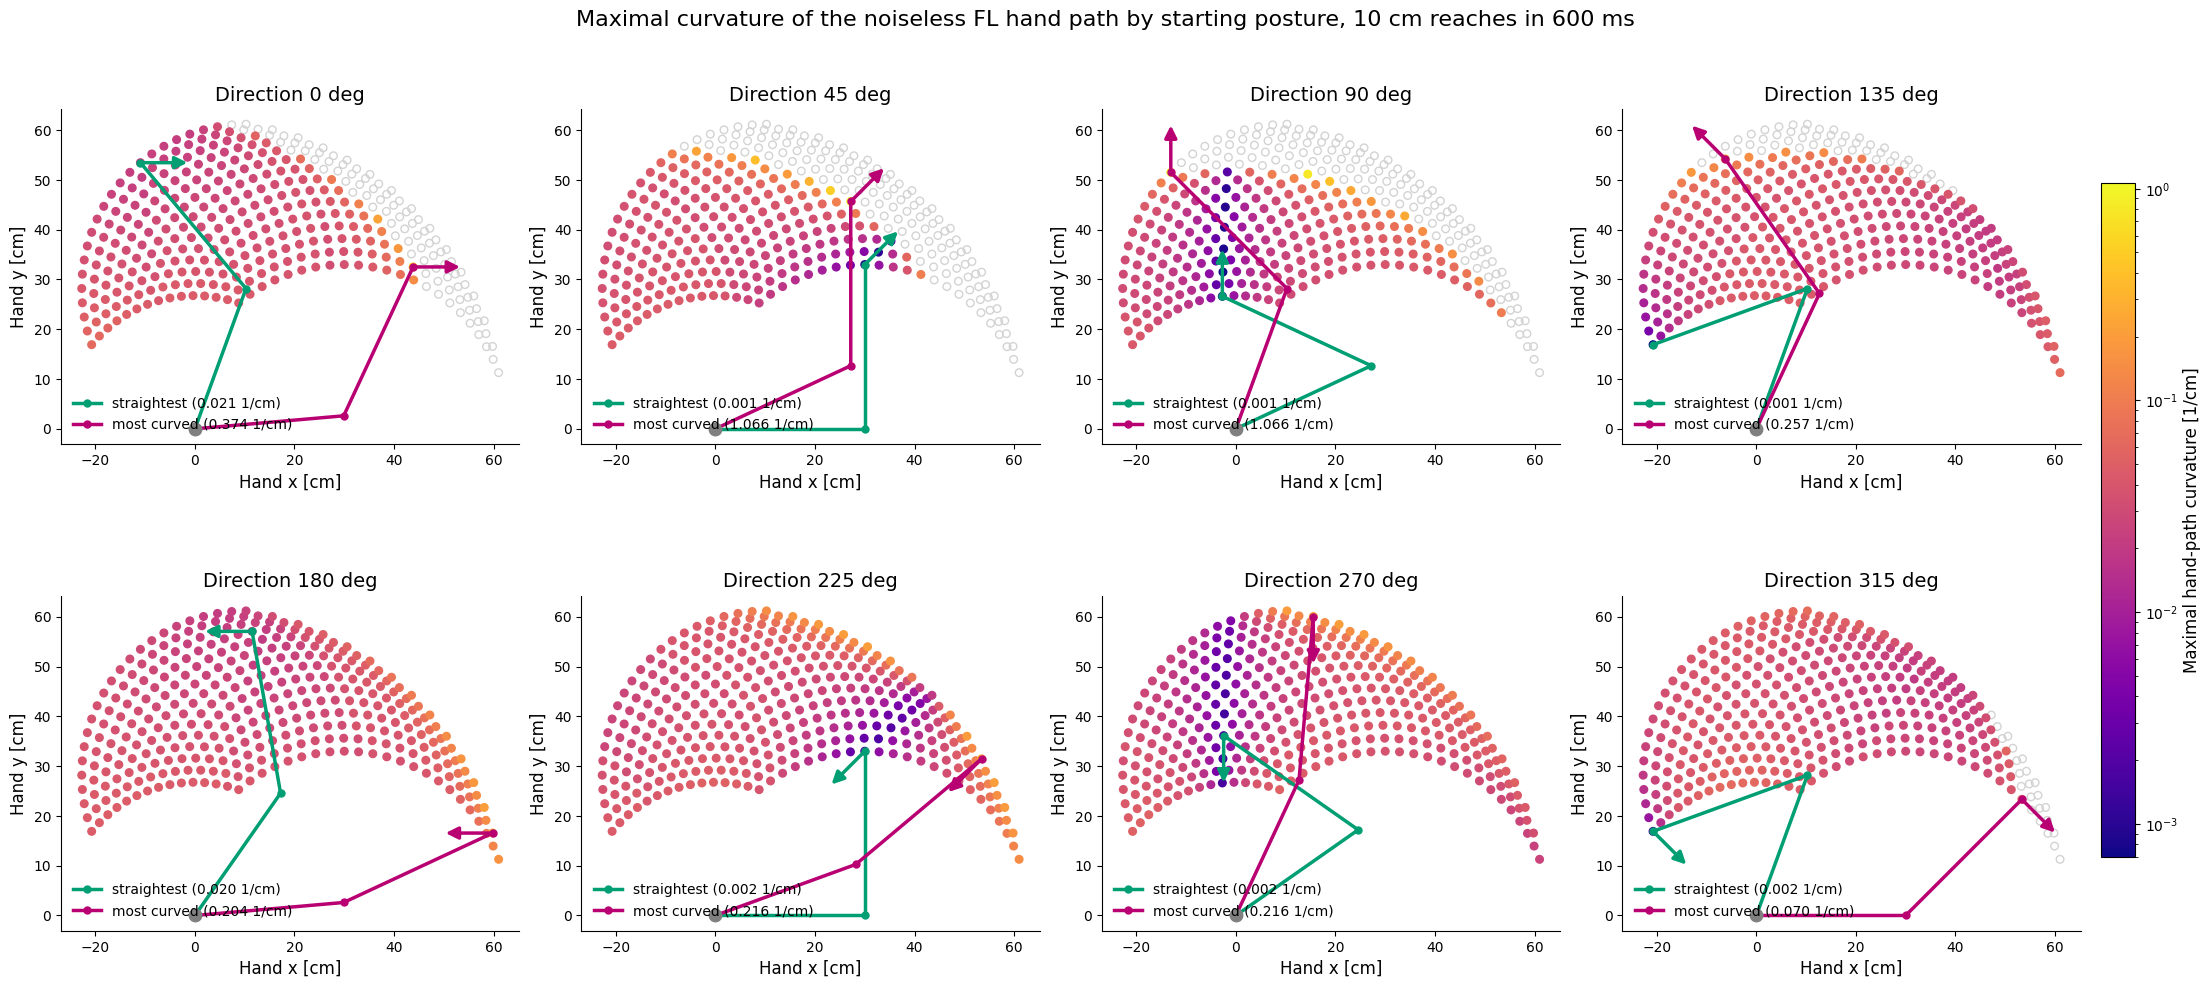

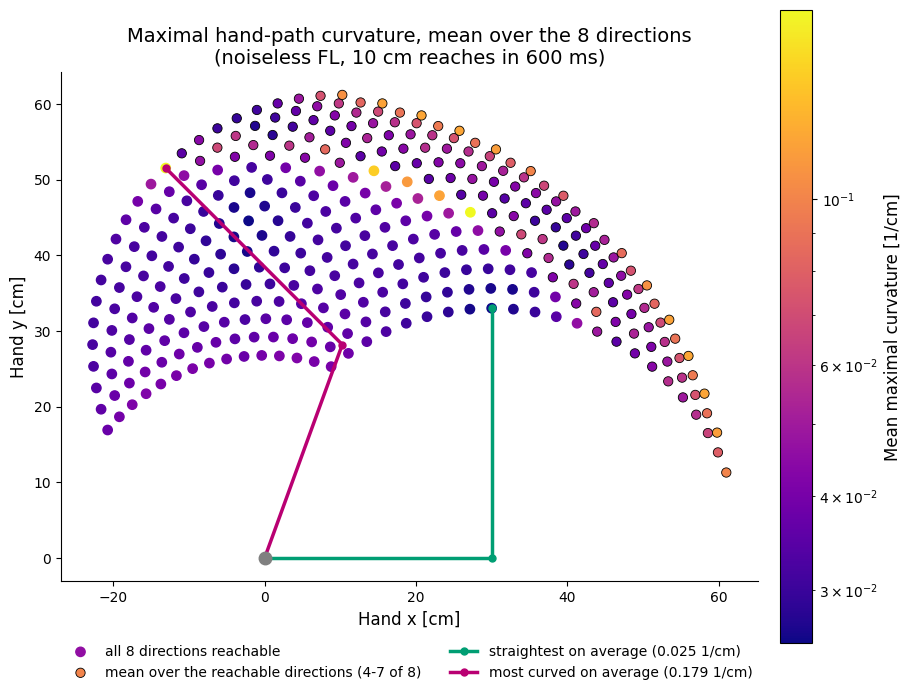

In [7]:
# The same figures for 10 cm reaches.
MAX_CURVATURE_10 = compute_max_curvature(10)
plot_curvature_directions(MAX_CURVATURE_10, 10)
plot_curvature_mean(MAX_CURVATURE_10, 10)